<a href="https://colab.research.google.com/github/ainankhan-pixel/231A052_NLP_Lab/blob/main/nlpASS1pj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install pandas scikit-learn matplotlib

In [2]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 120)
print("Libraries imported. Random seed:", SEED)

Libraries imported. Random seed: 42


In [3]:
data = [
    # meeting
    ("Can we meet tomorrow at 10 AM?", "meeting", "Yes, tomorrow at 10 AM works for me."),
    ("Are you free for a quick meeting this afternoon?", "meeting", "Yes, I can meet this afternoon."),
    ("Could we reschedule our meeting to Friday?", "meeting", "Friday works for me. What time suits you?"),
    ("Let us discuss this in a meeting next week.", "meeting", "Sounds good. Please share a suitable time."),
    ("I cannot attend the meeting today.", "meeting", "Thanks for letting me know. We can reschedule."),
    ("Please confirm whether the meeting is still on.", "meeting", "Yes, the meeting is still on."),
    # thanks
    ("Thank you for helping me with the report.", "thanks", "You're welcome! Happy to help."),
    ("Thanks a lot for your quick response.", "thanks", "You're welcome. Glad I could help."),
    ("I really appreciate your support.", "thanks", "You're very welcome!"),
    ("Many thanks for sharing the notes.", "thanks", "You're welcome. Hope they are useful."),
    ("Thanks for explaining the topic to me.", "thanks", "No problem at all!"),
    ("I am grateful for your assistance.", "thanks", "You're welcome. I'm glad I could assist."),
    # request
    ("Could you send me the assignment notes?", "request", "Sure, I'll send them to you."),
    ("Please share the project file when you can.", "request", "Of course, I'll share the project file."),
    ("Can you help me review this document?", "request", "Sure, send it over and I'll take a look."),
    ("Would you mind forwarding the meeting link?", "request", "Of course, I'll forward the link."),
    ("Please let me know the submission deadline.", "request", "I'll check and let you know."),
    ("Could you explain this question to me?", "request", "Sure, I'll try to explain it."),
    # apology
    ("Sorry for replying so late.", "apology", "No worries. Thanks for getting back to me."),
    ("I apologize for missing the deadline.", "apology", "Thanks for letting me know. Let's discuss next steps."),
    ("Sorry, I sent the wrong attachment.", "apology", "No problem. Please send the correct attachment."),
    ("I am sorry for the confusion.", "apology", "That's okay. Thanks for clarifying."),
    ("Please accept my apologies for the delay.", "apology", "No worries. I appreciate the update."),
    ("Sorry I could not attend yesterday.", "apology", "That's alright. Thanks for letting me know."),
    # confirmation
    ("I have uploaded the final document.", "confirmation", "Thanks for the update. I'll review it."),
    ("The payment has been completed.", "confirmation", "Thanks for confirming."),
    ("I submitted the form this morning.", "confirmation", "Got it, thanks for the update."),
    ("The task is finished now.", "confirmation", "Great, thanks for letting me know."),
    ("I have sent the email to the team.", "confirmation", "Thanks for the update."),
    ("The files are ready for review.", "confirmation", "Thanks. I'll review the files shortly."),
    # availability / refusal
    ("Can you take this task today?", "availability", "I'll check my schedule and let you know."),
    ("I am busy today but free tomorrow.", "availability", "Tomorrow works. What time is convenient?"),
    ("Could you help with this right now?", "availability", "I'll check if I can help right now."),
    ("I won't be available until Monday.", "availability", "Thanks for letting me know. We can plan for Monday."),
    ("Are you available to review my draft?", "availability", "Yes, please send me the draft."),
    ("I may need more time to finish this.", "availability", "No problem. Please share your expected timeline."),
    # greeting
    ("Hi, how are you doing?", "greeting", "Hi! I'm doing well, thanks. How are you?"),
    ("Hello, hope your week is going well.", "greeting", "Hello! Thanks, I hope yours is going well too."),
    ("Good morning!", "greeting", "Good morning! Hope you have a great day."),
    ("Hey, nice to hear from you.", "greeting", "Nice to hear from you too!"),
    ("Hi there, how is everything?", "greeting", "Everything is going well, thanks. How about you?"),
    ("Good afternoon, hope all is well.", "greeting", "Good afternoon! Thanks, I hope all is well with you too."),
]

df = pd.DataFrame(data, columns=["message", "intent", "reference_reply"])
print("Dataset rows:", len(df))
display(df.head(10))
print("\nIntent counts:")
display(df["intent"].value_counts().rename_axis("intent").reset_index(name="count"))

Dataset rows: 42


,message,intent,reference_reply
0,Can we meet tomorrow at 10 AM?,meeting,"Yes, tomorrow at 10 AM works for me."
1,Are you free for a quick meeting this afternoon?,meeting,"Yes, I can meet this afternoon."
2,Could we reschedule our meeting to Friday?,meeting,Friday works for me. What time suits you?
3,Let us discuss this in a meeting next week.,meeting,Sounds good. Please share a suitable time.
4,I cannot attend the meeting today.,meeting,Thanks for letting me know. We can reschedule.
5,Please confirm whether the meeting is still on.,meeting,"Yes, the meeting is still on."
6,Thank you for helping me with the report.,thanks,You're welcome! Happy to help.
7,Thanks a lot for your quick response.,thanks,You're welcome. Glad I could help.
8,I really appreciate your support.,thanks,You're very welcome!
9,Many thanks for sharing the notes.,thanks,You're welcome. Hope they are useful.



Intent counts:


,intent,count
0,meeting,6
1,thanks,6
2,request,6
3,apology,6
4,confirmation,6
5,availability,6
6,greeting,6


In [4]:
train_df, test_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df["intent"]
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Training examples: {len(train_df)}")
print(f"Test examples: {len(test_df)}")
display(test_df[["message", "intent", "reference_reply"]].head())

Training examples: 29
Test examples: 13


,message,intent,reference_reply
0,Many thanks for sharing the notes.,thanks,You're welcome. Hope they are useful.
1,I am grateful for your assistance.,thanks,You're welcome. I'm glad I could assist.
2,I submitted the form this morning.,confirmation,"Got it, thanks for the update."
3,Are you free for a quick meeting this afternoon?,meeting,"Yes, I can meet this afternoon."
4,"Hello, hope your week is going well.",greeting,"Hello! Thanks, I hope yours is going well too."


In [5]:
INTENT_RULES = {
    "meeting": [
        r"\bmeet(ing)?\b", r"\breschedul(e|ing)\b", r"\battend\b",
        r"\btime works\b", r"\bmeeting is still on\b"
    ],
    "thanks": [
        r"\bthank(s| you)?\b", r"\bappreciate\b", r"\bgrateful\b"
    ],
    "request": [
        r"\bcould you\b", r"\bwould you\b", r"\bplease\b",
        r"\bcan you\b", r"\bshare\b", r"\bsend me\b", r"\bforward\b"
    ],
    "apology": [
        r"\bsorry\b", r"\bapolog(y|ize|ise|ies)\b", r"\bmy apologies\b"
    ],
    "confirmation": [
        r"\buploaded\b", r"\bcompleted\b", r"\bsubmitted\b",
        r"\bfinished\b", r"\bsent the email\b", r"\bfiles are ready\b"
    ],
    "availability": [
        r"\bavailable\b", r"\bfree\b", r"\bbusy\b", r"\bright now\b",
        r"\bmore time\b", r"\bhelp with this\b"
    ],
    "greeting": [
        r"^\s*(hi|hello|hey|good morning|good afternoon)\b", r"\bhow are you\b",
        r"\bnice to hear from you\b"
    ],
}

REPLY_TEMPLATES = {
    "meeting": [
        "Yes, that works for me.",
        "Please share a suitable time.",
        "Thanks for checking. We can coordinate a time."
    ],
    "thanks": [
        "You're welcome!",
        "Happy to help.",
        "You're welcome. Glad it was useful."
    ],
    "request": [
        "Sure, I'll take a look.",
        "Of course, I'll send it when I can.",
        "Sure, could you share a few more details?"
    ],
    "apology": [
        "No worries. Thanks for letting me know.",
        "That's alright.",
        "Thanks for the update. Let's work out the next step."
    ],
    "confirmation": [
        "Thanks for the update.",
        "Got it, thank you.",
        "Great, I'll take a look."
    ],
    "availability": [
        "I'll check my schedule and let you know.",
        "Thanks for checking with me.",
        "Let's find a time that works."
    ],
    "greeting": [
        "Hi! How are you?",
        "Hello! Hope you're doing well.",
        "Hi there, nice to hear from you."
    ],
    "unknown": [
        "Thanks for your message.",
        "Could you share a little more detail?",
        "I'll get back to you soon."
    ]
}

def rule_predict_intent(message):
    text = message.lower()
    # First matching intent wins; this ordering is a limitation of simple rules.
    for intent, patterns in INTENT_RULES.items():
        if any(re.search(pattern, text) for pattern in patterns):
            return intent
    return "unknown"

def rule_replies(message):
    intent = rule_predict_intent(message)
    return intent, REPLY_TEMPLATES[intent][:3]

example_message = "Could you send me the assignment notes?"
print("Message:", example_message)
print("Predicted intent and suggestions:", rule_replies(example_message))

Message: Could you send me the assignment notes?
Predicted intent and suggestions: ('request', ["Sure, I'll take a look.", "Of course, I'll send it when I can.", 'Sure, could you share a few more details?'])


In [6]:
vectorizer = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2))
X_train = vectorizer.fit_transform(train_df["message"])

def retrieval_replies(message, top_k=3):
    query_vec = vectorizer.transform([message])
    similarities = cosine_similarity(query_vec, X_train).ravel()
    # Stable descending order; top_k retrieved training examples
    best_indices = np.argsort(-similarities)[:top_k]
    suggestions = []
    details = []
    for idx in best_indices:
        reply = train_df.loc[idx, "reference_reply"]
        if reply not in suggestions:
            suggestions.append(reply)
        details.append({
            "matched_message": train_df.loc[idx, "message"],
            "matched_intent": train_df.loc[idx, "intent"],
            "similarity": float(similarities[idx]),
            "reply": reply
        })
    while len(suggestions) < top_k:
        suggestions.append("Thanks for your message.")
    return suggestions[:top_k], details

print("Message:", example_message)
suggestions, matches = retrieval_replies(example_message)
print("Suggestions:")
for i, reply in enumerate(suggestions, 1):
    print(f"{i}. {reply}")
display(pd.DataFrame(matches))

Message: Could you send me the assignment notes?
Suggestions:
1. Sure, I'll send them to you.
2. Thanks. I'll review the files shortly.
3. That's okay. Thanks for clarifying.


,matched_message,matched_intent,similarity,reply
0,Could you send me the assignment notes?,request,1.0,"Sure, I'll send them to you."
1,The files are ready for review.,confirmation,0.0,Thanks. I'll review the files shortly.
2,I am sorry for the confusion.,apology,0.0,That's okay. Thanks for clarifying.


In [7]:
results = []

for _, row in test_df.iterrows():
    message = row["message"]
    true_intent = row["intent"]

    rule_intent, rule_suggestions = rule_replies(message)

    retrieval_suggestions, retrieval_details = retrieval_replies(message, top_k=3)
    retrieval_intent = retrieval_details[0]["matched_intent"] if retrieval_details else "unknown"

    results.append({
        "message": message,
        "true_intent": true_intent,
        "rule_intent": rule_intent,
        "rule_correct": rule_intent == true_intent,
        "rule_suggestions": " | ".join(rule_suggestions),
        "retrieval_intent": retrieval_intent,
        "retrieval_correct": retrieval_intent == true_intent,
        "retrieval_suggestions": " | ".join(retrieval_suggestions),
        "top_match_similarity": retrieval_details[0]["similarity"] if retrieval_details else 0.0,
        "reference_reply": row["reference_reply"]
    })

results_df = pd.DataFrame(results)
display(results_df[[
    "message", "true_intent", "rule_intent", "rule_correct",
    "retrieval_intent", "retrieval_correct", "top_match_similarity"
]])

metrics_df = pd.DataFrame([
    {
        "Approach": "A: Rule-based",
        "Test intent accuracy": accuracy_score(results_df["true_intent"], results_df["rule_intent"]),
        "Correct / test cases": f'{results_df["rule_correct"].sum()} / {len(results_df)}'
    },
    {
        "Approach": "B: TF-IDF retrieval",
        "Test intent accuracy": accuracy_score(results_df["true_intent"], results_df["retrieval_intent"]),
        "Correct / test cases": f'{results_df["retrieval_correct"].sum()} / {len(results_df)}'
    }
])
display(metrics_df)

,message,true_intent,rule_intent,rule_correct,retrieval_intent,retrieval_correct,top_match_similarity
0,Many thanks for sharing the notes.,thanks,thanks,True,request,False,0.333959
1,I am grateful for your assistance.,thanks,thanks,True,confirmation,False,0.000000
2,I submitted the form this morning.,confirmation,confirmation,True,greeting,False,0.598335
3,Are you free for a quick meeting this afternoon?,meeting,meeting,True,greeting,False,0.241848
4,"Hello, hope your week is going well.",greeting,greeting,True,greeting,True,0.322975
5,"Hey, nice to hear from you.",greeting,greeting,True,confirmation,False,0.000000
6,Could you explain this question to me?,request,request,True,confirmation,False,0.000000
7,Can you help me review this document?,request,request,True,confirmation,False,0.333959
8,I cannot attend the meeting today.,meeting,meeting,True,availability,False,0.321065
9,I may need more time to finish this.,availability,availability,True,confirmation,False,0.000000


,Approach,Test intent accuracy,Correct / test cases
0,A: Rule-based,0.846154,11 / 13
1,B: TF-IDF retrieval,0.076923,1 / 13


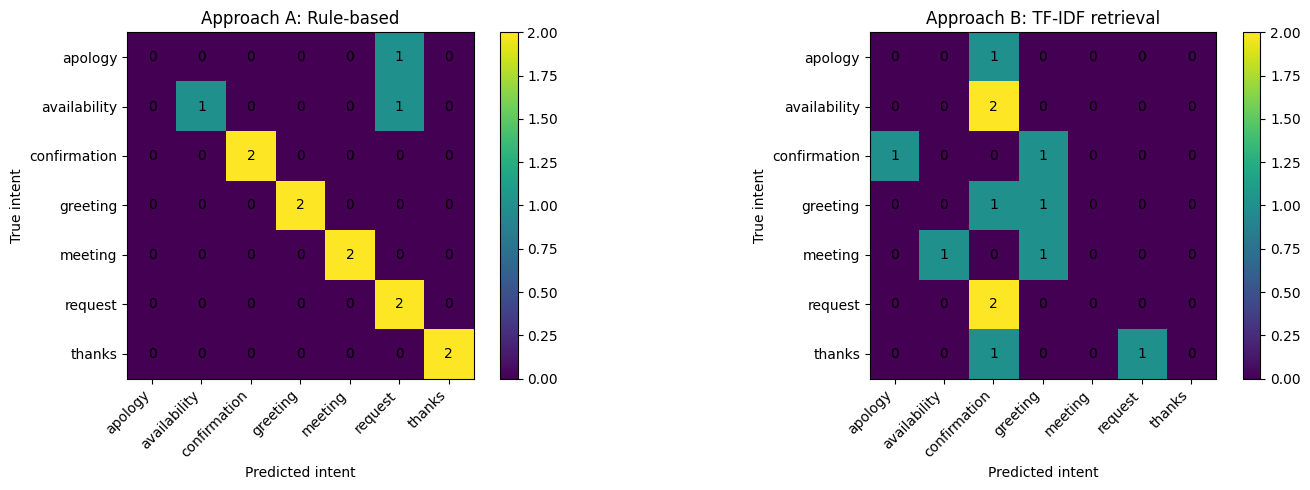

Approach A classification report
              precision    recall  f1-score   support

     apology       0.00      0.00      0.00         1
availability       1.00      0.50      0.67         2
confirmation       1.00      1.00      1.00         2
    greeting       1.00      1.00      1.00         2
     meeting       1.00      1.00      1.00         2
     request       0.50      1.00      0.67         2
      thanks       1.00      1.00      1.00         2

    accuracy                           0.85        13
   macro avg       0.79      0.79      0.76        13
weighted avg       0.85      0.85      0.82        13

Approach B classification report
              precision    recall  f1-score   support

     apology       0.00      0.00      0.00         1
availability       0.00      0.00      0.00         2
confirmation       0.00      0.00      0.00         2
    greeting       0.33      0.50      0.40         2
     meeting       0.00      0.00      0.00         2
     request

In [8]:
labels = sorted(set(results_df["true_intent"]) | set(results_df["rule_intent"]) | set(results_df["retrieval_intent"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, pred_col, title in [
    (axes[0], "rule_intent", "Approach A: Rule-based"),
    (axes[1], "retrieval_intent", "Approach B: TF-IDF retrieval")
]:
    cm = confusion_matrix(results_df["true_intent"], results_df[pred_col], labels=labels)
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Predicted intent")
    ax.set_ylabel("True intent")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print("Approach A classification report")
print(classification_report(
    results_df["true_intent"], results_df["rule_intent"],
    labels=labels, zero_division=0
))
print("Approach B classification report")
print(classification_report(
    results_df["true_intent"], results_df["retrieval_intent"],
    labels=labels, zero_division=0
))

In [9]:
def diagnose_error(message, true_intent, predicted_intent):
    text = message.lower()
    if predicted_intent == "unknown":
        return "Unmatched wording / rule coverage"
    if true_intent != predicted_intent:
        if any(term in text for term in ["could you", "please", "can you", "would you"]):
            return "Intent overlap: request phrasing"
        if any(term in text for term in ["tomorrow", "today", "meeting", "friday"]):
            return "Context or meeting-keyword overlap"
        return "Intent classification mismatch"
    return "No intent mismatch"

error_rows = []
for _, row in results_df.iterrows():
    for approach, pred_col in [("Rule-based", "rule_intent"), ("TF-IDF retrieval", "retrieval_intent")]:
        pred = row[pred_col]
        if pred != row["true_intent"]:
            error_rows.append({
                "Approach": approach,
                "Message": row["message"],
                "True intent": row["true_intent"],
                "Predicted intent": pred,
                "Likely error category": diagnose_error(row["message"], row["true_intent"], pred)
            })

error_df = pd.DataFrame(error_rows, columns=[
    "Approach", "Message", "True intent", "Predicted intent", "Likely error category"
])
if error_df.empty:
    print("No intent mismatches occurred on this particular split. Inspect reply quality manually too.")
else:
    display(error_df)

,Approach,Message,True intent,Predicted intent,Likely error category
0,TF-IDF retrieval,Many thanks for sharing the notes.,thanks,request,Intent classification mismatch
1,TF-IDF retrieval,I am grateful for your assistance.,thanks,confirmation,Intent classification mismatch
2,TF-IDF retrieval,I submitted the form this morning.,confirmation,greeting,Intent classification mismatch
3,TF-IDF retrieval,Are you free for a quick meeting this afternoon?,meeting,greeting,Context or meeting-keyword overlap
4,TF-IDF retrieval,"Hey, nice to hear from you.",greeting,confirmation,Intent classification mismatch
5,TF-IDF retrieval,Could you explain this question to me?,request,confirmation,Intent overlap: request phrasing
6,TF-IDF retrieval,Can you help me review this document?,request,confirmation,Intent overlap: request phrasing
7,TF-IDF retrieval,I cannot attend the meeting today.,meeting,availability,Context or meeting-keyword overlap
8,TF-IDF retrieval,I may need more time to finish this.,availability,confirmation,Intent classification mismatch
9,TF-IDF retrieval,I have sent the email to the team.,confirmation,apology,Intent classification mismatch


In [10]:
display(results_df[[
    "message", "reference_reply",
    "rule_suggestions", "retrieval_suggestions",
    "true_intent", "rule_intent", "retrieval_intent"
]].reset_index(drop=True))

,message,reference_reply,rule_suggestions,retrieval_suggestions,true_intent,rule_intent,retrieval_intent
0,Many thanks for sharing the notes.,You're welcome. Hope they are useful.,You're welcome! | Happy to help. | You're welcome. Glad it was useful.,"Sure, I'll send them to you. | No problem at all! | You're welcome. Glad I could help.",thanks,thanks,request
1,I am grateful for your assistance.,You're welcome. I'm glad I could assist.,You're welcome! | Happy to help. | You're welcome. Glad it was useful.,Thanks. I'll review the files shortly. | I'll check my schedule and let you know. | That's okay. Thanks for clarifying.,thanks,thanks,confirmation
2,I submitted the form this morning.,"Got it, thanks for the update.","Thanks for the update. | Got it, thank you. | Great, I'll take a look.",Good morning! Hope you have a great day. | Thanks. I'll review the files shortly. | That's okay. Thanks for clarifying.,confirmation,confirmation,greeting
3,Are you free for a quick meeting this afternoon?,"Yes, I can meet this afternoon.","Yes, that works for me. | Please share a suitable time. | Thanks for checking. We can coordinate a time.","Good afternoon! Thanks, I hope all is well with you too. | Tomorrow works. What time is convenient? | You're welcome...",meeting,meeting,greeting
4,"Hello, hope your week is going well.","Hello! Thanks, I hope yours is going well too.","Hi! How are you? | Hello! Hope you're doing well. | Hi there, nice to hear from you.","Good afternoon! Thanks, I hope all is well with you too. | Sounds good. Please share a suitable time. | Thanks. I'll...",greeting,greeting,greeting
5,"Hey, nice to hear from you.",Nice to hear from you too!,"Hi! How are you? | Hello! Hope you're doing well. | Hi there, nice to hear from you.",Thanks. I'll review the files shortly. | I'll check my schedule and let you know. | That's okay. Thanks for clarifying.,greeting,greeting,confirmation
6,Could you explain this question to me?,"Sure, I'll try to explain it.","Sure, I'll take a look. | Of course, I'll send it when I can. | Sure, could you share a few more details?",Thanks. I'll review the files shortly. | I'll check my schedule and let you know. | That's okay. Thanks for clarifying.,request,request,confirmation
7,Can you help me review this document?,"Sure, send it over and I'll take a look.","Sure, I'll take a look. | Of course, I'll send it when I can. | Sure, could you share a few more details?","Thanks for the update. I'll review it. | Yes, please send me the draft. | Thanks. I'll review the files shortly.",request,request,confirmation
8,I cannot attend the meeting today.,Thanks for letting me know. We can reschedule.,"Yes, that works for me. | Please share a suitable time. | Thanks for checking. We can coordinate a time.","I'll check my schedule and let you know. | That's alright. Thanks for letting me know. | Yes, the meeting is still on.",meeting,meeting,availability
9,I may need more time to finish this.,No problem. Please share your expected timeline.,I'll check my schedule and let you know. | Thanks for checking with me. | Let's find a time that works.,Thanks. I'll review the files shortly. | I'll check my schedule and let you know. | That's okay. Thanks for clarifying.,availability,availability,confirmation


In [11]:
new_message = "Could you share the project file with me?"

rule_intent, rule_suggestion_list = rule_replies(new_message)
retrieval_suggestion_list, retrieval_match_details = retrieval_replies(new_message, top_k=3)

print("INPUT:", new_message)
print("\nAPPROACH A — RULE-BASED")
print("Detected intent:", rule_intent)
for i, reply in enumerate(rule_suggestion_list, 1):
    print(f"{i}. {reply}")

print("\nAPPROACH B — TF-IDF RETRIEVAL")
for i, reply in enumerate(retrieval_suggestion_list, 1):
    print(f"{i}. {reply}")

print("\nNearest training examples:")
display(pd.DataFrame(retrieval_match_details))

INPUT: Could you share the project file with me?

APPROACH A — RULE-BASED
Detected intent: request
1. Sure, I'll take a look.
2. Of course, I'll send it when I can.
3. Sure, could you share a few more details?

APPROACH B — TF-IDF RETRIEVAL
1. Of course, I'll share the project file.
2. Thanks. I'll review the files shortly.
3. I'll check my schedule and let you know.

Nearest training examples:


,matched_message,matched_intent,similarity,reply
0,Please share the project file when you can.,request,1.0,"Of course, I'll share the project file."
1,The files are ready for review.,confirmation,0.0,Thanks. I'll review the files shortly.
2,Can you take this task today?,availability,0.0,I'll check my schedule and let you know.


In [12]:
df.to_csv("smart_reply_demo_dataset.csv", index=False)
results_df.to_csv("smart_reply_test_results.csv", index=False)
metrics_df.to_csv("smart_reply_metrics.csv", index=False)
error_df.to_csv("smart_reply_error_analysis.csv", index=False)

print("Saved:")
for filename in [
    "smart_reply_demo_dataset.csv",
    "smart_reply_test_results.csv",
    "smart_reply_metrics.csv",
    "smart_reply_error_analysis.csv"
]:
    print(" -", filename)

Saved:
 - smart_reply_demo_dataset.csv
 - smart_reply_test_results.csv
 - smart_reply_metrics.csv
 - smart_reply_error_analysis.csv


In [13]:
try:
    from google.colab import files
    for filename in [
        "smart_reply_demo_dataset.csv",
        "smart_reply_test_results.csv",
        "smart_reply_metrics.csv",
        "smart_reply_error_analysis.csv"
    ]:
        files.download(filename)
except ImportError:
    print("Google Colab download helper not available. CSV files remain in the current directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>